<a href="https://colab.research.google.com/github/vasavibantupalli-web/DataAnalysis_Codegnan2026/blob/main/STATISTICS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# create the classroom dataset
# Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
students = pd.DataFrame({
    "student_id" : [101,102,103,104,105,106],
    "course" : [ "DA", "PFS", "DA", "PFS","DA", "DA"],
    "hours" : [5,8,3,10,6,7],
    "score" : [ 55, 70, 40, 85, 65, 75],
    "satisfaction" : ["satisfied", "very satisfied", "neutral", "satisfied","very satisfied", "satisfied"]
})
print(students)

   student_id course  hours  score    satisfaction
0         101     DA      5     55       satisfied
1         102    PFS      8     70  very satisfied
2         103     DA      3     40         neutral
3         104    PFS     10     85       satisfied
4         105     DA      6     65  very satisfied
5         106     DA      7     75       satisfied


In [ ]:
print("shape",students.shape)
print(type(students))
print(students.dtypes)
print(students.size)
print(students.ndim)
print(type(students.values))
print("missing values:",students.isna().sum())

shape (6, 5)
<class 'pandas.core.frame.DataFrame'>
student_id        int64
course           object
hours             int64
score             int64
statification    object
dtype: object
30
2
<class 'numpy.ndarray'>
missing values: student_id       0
course           0
hours            0
score            0
statification    0
dtype: int64


In [ ]:
# count categories and summerise the Numerical columns
print("students per course count:",students['course'].value_counts())
print(students[['hours','score']])
print(students[['hours','score']].describe()) # Descriptive statics  imformation
# Observe the Students proportion
print((students['course'] == "DA").mean())
print((students['course'] == "PFS").mean())

students per course count: course
DA     4
PFS    2
Name: count, dtype: int64
   hours  score
0      5     55
1      8     70
2      3     40
3     10     85
4      6     65
5      7     75
           hours      score
count   6.000000   6.000000
mean    6.500000  65.000000
std     2.428992  15.811388
min     3.000000  40.000000
25%     5.250000  57.500000
50%     6.500000  67.500000
75%     7.750000  73.750000
max    10.000000  85.000000
0.6666666666666666
0.3333333333333333


In [ ]:
# Python central tendency and Interpretation
values = np.array([12,15,15,18,20,22,22,22,25,90])
mean_value = np.mean(values)
median_value = np.median(values)
mode_value = pd.Series(values).mode().tolist()
print("mean:",mean_value)
print("Median:",median_value)
print("Mode:",mode_value)
print("sorted values",np.sort(values))

mean: 26.1
Median: 21.0
Mode: [22]
sorted values [12 15 15 18 20 22 22 22 25 90]


In [ ]:
#manual calculation -->sensitivity in the information-->spread outliers and relationship
#connect the library result to the manual calcn
values= np.array([12,15,15,18,20,22,22,22,25,90])
total=np.sum(values)
print(total)
count=len(values)
print(count)
manual_mean=total / count
print(f'Manual mean calculation result is{manual_mean}')
#manual median calculation
ordered = np.sort(values)
middle = count //2  #10/2=5
manual_median = (ordered[middle-1]+ordered[middle])/2


261
10
Manual mean calculation result is26.1


In [ ]:
#demonstrate the sensitivity to an extreme value
print(values)
#exclude 90 only for a comparision ,retaining the original array
comparision_values = values[values!=90]
comparision_values
print("Original Mean",np.mean(values))
print("Mean Excluding 90:",np.mean(comparision_values))
#Expected 26.1 and 19.0--> the boolean mask selects values that differ from 90,

[12 15 15 18 20 22 22 22 25 90]
Original Mean 26.1
Mean Excluding 90: 19.0


In [ ]:
#python spread outliers and relationships
scores_a = np.array([58,60,62])
scores_b = np.array([20,60,100])
for name,scores in [("Akash",scores_a),("Sanjay",scores_b)]:
  print(name,scores)
  print(name,"Mean=",np.mean(scores),
       "Range:",np.max(scores)-np.min(scores),
       "population std",round(np.std(scores),2))
  #standard deviation --> it quantifies the amount of variation or spread in a set of
  #data points relative to its mean
  #low standard deviation--> indicates that the datapoints tned to be very close to mean
  #high standard deviation-->indicates that the data points are spread a wider range

Akash [58 60 62]
Akash Mean= 60.0 Range: 4 population std 1.63
Sanjay [ 20  60 100]
Sanjay Mean= 60.0 Range: 80 population std 32.66


In [ ]:
#flag unusual values using the IQR(inter quantile range)
print(values)
q1,q3 = np.percentile(values,[25,75])
print(q1)
print(q3)
iqr = q3-q1 #--> lower quartile, Q3--> upper quartile
print(iqr)
lower = q1-(1.5)*iqr
upper = q3-(1.5)*iqr
print(lower)
print(upper)
flagged = values[(values<lower) | (values>upper)]
print("Q1:",q1,"Q3:",q3,"IQR:",iqr)
print("fences:",lower,upper)
print("flagged values(s) [outliers]:",flagged)

[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
12.625
Q1: 15.75 Q3: 22.0 IQR: 6.25
fences: 6.375 12.625
flagged values(s) [outliers]: [15 15 18 20 22 22 22 25 90]


pearson correlation: 0.963


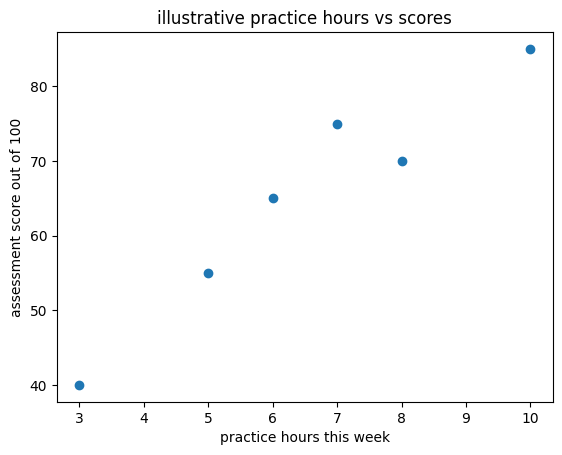

In [ ]:
#exploring numerical relationship
import matplotlib.pyplot as plt
result = students["hours"].corr(students['score']) #peasorn correlation
#pearson correlation(r)--> it is a statistical measure that quantifies the
#strenght and direction of a linear relationship between two continuous variables
#+1.0--?perfectly positive-->as variable x increases, y also increases in a perfect
#st.line
#-1.0--perfectly negative
#0.0(no linear correlation)
result
print("pearson correlation:",round(result,3))
plt.scatter(students["hours"],students["score"])
plt.xlabel("practice hours this week")
plt.ylabel("assessment score out of 100")
plt.title("illustrative practice hours vs scores")
plt.show()


In [ ]:
#datatypes, central tendency and a first look at spread
#variance,standard deviation, quartiles and the iqr rule
#range-->first measure of sapread--> range = maximum-minimum
#student a --> scores --> 58,60,62 --> mean-->60-->deviations-->-2,0,2
#student b --> scores --> 20,60,100 --> mean-->60-->deviations-->-40,0,40
#for both students,the deviations add to zero.averaged signed deviuations would hide the
#spread.squaring makes the contributions non negative and gives greater weight to larger
#deviations
#scores -->a--. deviation as follows
'''
scores x      mean.          deviation (x-mean)          square deviations
58            60             -2                          4
60            60             0                           0
62            60             2                           4

total sq deviation = 4+0+4=8-->population variance = 8/3 =2.667 marks squared
population variance = sum of squared deviations/N
population stnadard deviation = square root[summation(xi-u)**2]/N #xi--> each individual value
u--->population mean
population std deviation
'''
print(scores_a)
print(scores_b)
mean_a = np.mean(scores_a)
print(mean_a)
deviations = scores_a - mean_a
print(deviations)
squared_deviations = deviations**2
squared_total = np.sum(squared_deviations)
print(squared_total)
variance_a = squared_total/len(scores_a)
print(variance_a)
std_a = np.sqrt(variance_a)
print(std_a)

[58 60 62]
[ 20  60 100]
60.0
[-2.  0.  2.]
8.0
2.6666666666666665
1.632993161855452


In [ ]:
#comparing both scores and both denominators
for name,scores in [("A",scores_a),('B',scores_b)]:
 print(name,"range",np.ptp(scores),
    "Pop Std",np.std(scores),
      "Sample Std",np.std(scores,ddof=1))

A range 4 Pop Std 1.632993161855452 Sample Std 2.0
B range 80 Pop Std 32.65986323710904 Sample Std 40.0


In [ ]:
#Quartiles IQR and outliers screening
#values
q1,median,q3 = np.percentile(values,
                             [25,50,75],
                             method="linear")
print(q1)
print(q3)
print(median)
iqr= q3-q1
print(iqr)
lower_fence = q1-1.5*iqr
upper_fence = q3+1.5*iqr
outlier_mask = ((values<lower_fence) | (values>upper_fence))
print("flagged values:",values[outlier_mask])

15.75
22.0
21.0
6.25
flagged values: [90]


In [ ]:
#preserve the observations with review labels
review = pd.DataFrame({
    "Observations_Id" : np.arange(1,len(values)+1),
    "Value":values,
    "IQR_Flag":outlier_mask
})
review

,Observations_Id,Value,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
d = print(review.to_string(index=False))
print(d)
print(type(d))

 Observations_Id  Value  IQR_Flag
               1     12     False
               2     15     False
               3     15     False
               4     18     False
               5     20     False
               6     22     False
               7     22     False
               8     22     False
               9     25     False
              10     90      True
None
<class 'NoneType'>


In [ ]:
print("Flagged IDs",review.loc[review["IQR_Flag"],
                               "Observations_Id"].tolist())

Flagged IDs [10]


In [ ]:
print(upper_fence)
print(lower_fence)

31.375
6.375


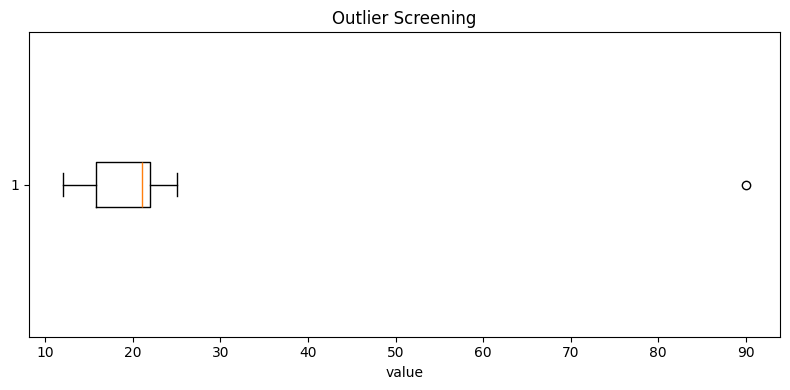

In [ ]:
#python box and whisker plot
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(8,4))
ax.boxplot(values,vert=False,whis=2.5)
ax.set_xlabel("value")
ax.set_title("Outlier Screening")
fig.tight_layout()
plt.show()
#experting a box from 15.75 to 22 a median at 21, and seperate marker at 90 which indicates
#outliers, with whiskers pointing at 6.375 and upper_fence at 31.375

In [ ]:
 #explain sensitivity without deleting a data
comparision = values[~outlier_mask]
comparision
print("All Mean",np.mean(values))
print("Comparision Mean",np.mean(comparision))
print("All Median",np.median(values))
print("Comparision Median",np.median(comparision))
# comparision is only used to demostrate the sensitivity values and review still preserve
#original values

All Mean 26.1
Comparision Mean 19.0
All Median 21.0
Comparision Median 20.0


signed deviations cancel and squared
deviations reveal spread
variance used squared units,STD used
original units
IQR fences and box and whisker plot
endpoints are important
outlier detection creates a review flag,not
a deletion instruction

In [ ]:
#positive and negative covariance using paired deviations
#pearson correlations from covariance and standard deviations
#linear association  from monotonic association and causation
#python to verify the calculations and inspect scaterr plots
students

,student_id,course,hours,score,statification
0,101,DA,5,55,satisfied
1,102,PFS,8,70,very satisfied
2,103,DA,3,40,neutral
3,104,PFS,10,85,satisfied
4,105,DA,6,65,very satisfied
5,106,DA,7,75,satisfied


In [ ]:
# create a new observation table
# create a new observation table
data = pd.DataFrame({
    "observation":np.arange(1,7),
    "Practice_Hours":[2,4,8,7,8,10],
    "Assessment score":[35,48,55,68,74,90]
})
print(data)

   observation  Practice_Hours  Assessment score
0            1               2                35
1            2               4                48
2            3               8                55
3            4               7                68
4            5               8                74
5            6              10                90


In [ ]:
#variance--> multiples a variables deviation by itself
#covariance--> multiples the deviation in x by the paired deviation in v
'''
x deviation           y deviation       product     contribution
positive               positive         positive    both above their means
negative               negative         positive    both below their means
positive               negative         negative    opposite sides of their means
negative               positive         negative    opposite sides of their means

population covariance = sum of (xi - population mean of x) * (yi - population mean of y)
                -------------------------------------------------------------------
                                 N
sample covariance = sum of(xi - sample mean of x) * (yi - sample mean of y)/N-1

xi and yi are paired values,N is population size, n is the sample size
'''
data[['Practice_Hours','Assessment score']]
# x - mean x (Hour ----> x)
# x1---> x1-meanx ---> 2 - 6 ----> -4
# x2 ---> 4-6 ---> -2
# x3 ---> 5-6 ---> -1
# x4 ---> 1
# x5 ---> 2
# x6 ---> 4
# y - mean_y ---> (scores --->y) ---> mean_y ----> 61.67
# y1 -->-26.67
# y2 -->-13.67
# y3 -->-6.67
# y4 -->6.33
# y5 -->12.333
# y6 -->28.33
#product--> x1*y1->106.67
#x2*y2-->27.33
#x3*y3-->6.67
#x4*y4-->6.33 x5*y5-->24.67 x6*y6--> 113.33
#sum of deviation products = 285. -->population cov=285/6 -->47.5.
#sample covariance = 285/5 -->57
#both are positive,indication is more hrs higher score



,Practice_Hours,Assessment score
0,2,35
1,4,48
2,8,55
3,7,68
4,8,74
5,10,90


In [ ]:
#Python Covariance
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'Scores':scores})
print(data)
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#Cal covariance from deviations
#We will create the variables as per formula
n = len(hours)
dx = hours - np.mean(hours)
print(dx)
dy = scores - np.mean(scores)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total / n
sample_cov = cross_total / (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)


   Hours  Scores
0    2.0    35.0
1    4.0    48.0
2    5.0    55.0
3    7.0    68.0
4    8.0    74.0
5   10.0    90.0
Shape is: (6, 2)
Missing Values: {'Hours': 0, 'Scores': 0}
[-4. -2. -1.  1.  2.  4.]
[-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
Product Total 285.0
Population Covariance 47.5
Sample Covariance 57.0


Why Standardise Covariance --> A Covariance changes in above case if hours are expressed in minutes..

Correlation divides the Covariance by Standard Deviations of both variables so that the units cancel and mainly values lies b/w -1 and +1,provided both variables have nonzero variation Sample Pearson Correlation = (r) = Sample Covariance (X,Y) / (Sample Std Deviation of X * Sample Std Deviation of Y)...

for above observations,sample variance of hours --> Summation (xi - mean_x)**2 / n-1 --> (2-6)**2 + (4-6)**2 + (5-6)**2 + (7-6)**2 + (8-6)**2 + (10-6)**2 / 5 -->16 + 4 + 1 + 1 + 4 + 16 / 5 -> 8.4

Sample Std Deviation --> Sqrt(Sample Variance). --> 2.89

Sample variance of scores -> 387.466 Sample Std Deviation --> 19.6

Sample Pearson Correlation(r) = 57 /(2.89 *19.6) --> ~1 This describes a very strong positive linear association in given 6 observations...

Covariance comapred with correlation Property. Covaraince. Pearson Correlation -->Units Product of two units. unitless -->Range. No fixed bounds. -1 to +1 defined -->Positive unit rescaling changes magnitude unchanged --> Purpose. Describes Joint variation. Describe linear association (direction and strength)

A negative rescaling reverses the correlation sign.Adding a constant to either variable leaves Pearson Correlation unchanged..

In [ ]:
#Verify and Standardise
cov_matrix = np.cov(hours,scores,ddof=1)
print(cov_matrix)
r_manual = sample_cov / (np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r = np.corrcoef(hours,scores)[0,1]
print(f'Manual r is {round(r_manual,4)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[  8.4         57.        ]
 [ 57.         387.46666667]]
Manual r is 0.9991
Using Numpy value of r is 0.9991


In [ ]:
#Ranks adn Careful Analytical conclusions
#Pearson and Spearman
#Pearson measures linear association between numerical variables
#Spearman is Pearson Correlation of the ranks and measures monotonic association;whther the values are
#consistently tend to increase together or move in opposite...
#Montonic --> It is a trend where two variables move in a concise relative direction,but not
#necessarily at a constant rate...
#Linear -->Perfect St.line
#Monotonic -->can be straight line or a  curve that never reverses direction

#For x = [1,2,3,4,5], y = [1,4,9,16,25] both rank lists --> [1,2,3,4,5],
#Spearman Correlation -->1
#Pearson Correlation --> 0.99
#pandas --> rank() assigns average ranks by default

In [ ]:
#Python unit changes ranks and edge cases
minutes = hours * 60
print(minutes)
cov_minutes = np.cov(minutes,scores)[0,1]
print(cov_minutes)
r_minutes = np.corrcoef(minutes,scores)
print(r_minutes)
print("Pandas Correlation:",data.corr())
#We have receieved Expected Covaraince as 3420 minutes * marks --> Correlation is making
#same value around 0.9991

#Cal Spearman through ranks
x_rank_demo = pd.Series([1,2,3,4,5])
y_rank_demo = pd.Series([1,4,9,16,25])
pearson_demo = x_rank_demo.corr(y_rank_demo)
print(pearson_demo)
x_ranks = x_rank_demo.rank()
print("X ranks",x_ranks)
y_ranks = y_rank_demo.rank()
print("Y ranks",y_ranks)
print("Spearman:",round(x_ranks.corr(y_ranks),4))

[120. 240. 300. 420. 480. 600.]
3420.0
[[1.         0.99912089]
 [0.99912089 1.        ]]
Pandas Correlation:            Hours    Scores
Hours   1.000000  0.999121
Scores  0.999121  1.000000
0.981104910251593
X ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Y ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Spearman: 1.0


[-2. -1.  0.  1.  2.]
[4. 1. 0. 1. 4.]
0.0


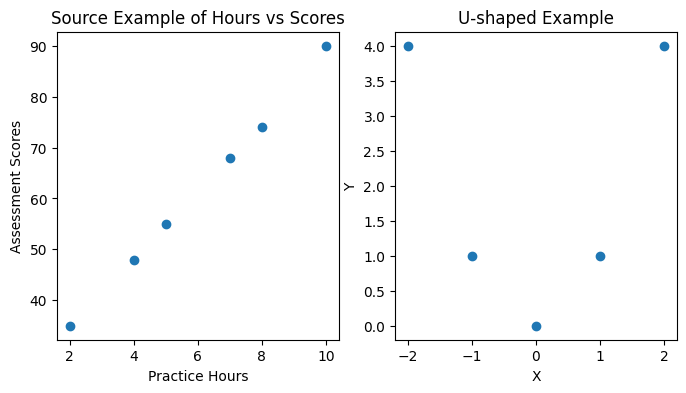

In [ ]:
#Python Scatter plots and nonlinear plots
#Compare a line-like pattern with curve
curve_x = np.array([-2,-1,0,1,2],dtype=float)
curve_y = curve_x**2
print(curve_x)
print(curve_y)
curve_r = np.corrcoef(curve_x,curve_y)[0,1]
print(curve_r) #indicates that complete absence of linear or montonic relationship
#display the plot for above mentioned data
fig,axes = plt.subplots(1,2,figsize=(8,4))
axes[0].scatter(hours,scores)
axes[0].set(xlabel="Practice Hours",
            ylabel ="Assessment Scores",title="Source Example of Hours vs Scores")
axes[1].scatter(curve_x,curve_y)
axes[1].set(xlabel="X",ylabel="Y",title="U-shaped Example")
plt.show()

In [ ]:
#for x = [1,2,3] and y = [2,4,6],find both covariance formulas and pearson r


probability Distributions -->
it describes the possible values of a random variable and how does probability is assigned to them..
it connects uncertainity to the mean variance and standard deviation which we have discussed.
random experiment--> it has an outcome that is not known with certainity inadvance. random values will assign a numerical value to each outcome..... we use x for variable..
x or k denotes for possible result
for one assessment let x = 1(pass),x=0 otherwise--> let y be number of passes..
let T be time completion in minutes..
discrete  ---> a finite or countability infinite set
in a minute

continous --> any value in a continous
interval --> task duratioin in minutesobserved frequency describe a datasetprobability model will describe a proposed mechanism
that generates obsrvations...
Eg: 6 passes out of 10 attempts -->
proportion-->6 /10 -->0.6
a small dataset will not establish exct probability for every future dataset..

PMF,PDF,CDF -->
PMF--> PROBABILITIY MASS FUNCTION
--> it gives the exact probability that a discrete random variable equals to a specific value
p(x) = p(X=x)
--> every probablitiy outcome must be between o and 1
--> the sum of all probabilities across all possible values should  be equal to 1
-->rolling a 3 unfair six sided die
p(X=3) = 1/6

PDF -->PROBABILITY DENSITY FUNCTION
--> it describes the probability density
(likelihood per unit length) of a continous random variable...(measures like height ,weight,time..)
--> probability of a continous variable taking one exact single point always p(X=x) = 0
--> it is calculated by areaa under the curve..
--> person's height falling between  160cms to 180cms by integrating PDFover that range..

CDF--> CUMULATIVE DENSITY FUNCTION
--> it describes the cumulative probability that a random variable is less than or equal to given value (x) --> F(x) = p(X<=x)
-->can be applied for both discerete and continous CDF values 0 and 1
--> discrete variables --> it forms a step function
-->, continous vatiables
--> it is a smooth,Ssmoothed curve

In [ ]:
import numpy as np
#!pip install scipy
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
#Bernoulli Distribution--> it models one trial with two possiblw outcomes
#1 for success,0 for Failure
#p(X=x) = p^(1-p)^1-x, xE {0,1}
#p--> probability of X=1; 0<=p<=1
#support--> 0 and 1
#mean -->p; variance  --> p(1-p); std -->sqrt(p(1-p))
p=0.6 #model assigns probability to pass one assessment
pass_prob = stats.bernoulli.pmf(1,p)
fail_prob = stats.bernoulli.pmf(0,p)
bernoulli_mean = p
bernoulli_var = p*(1-p)
print(f'pass:',round(pass_prob,4))
print(f'fail:',round(fail_prob,4))
print(f'mean:',bernoulli_mean)
print("variance:",bernoulli_var)
print("standard deviation:",round(np.sqrt(bernoulli_var),4))
#p sets the success probability,pass_prob and fail_prob --> exact probabilites
#bernoulli_var describes

pass: 0.6
fail: 0.4
mean: 0.6
variance: 0.24
standard deviation: 0.4899


#continous distribution--> normal distrbution,uniform distribution..
assessment scores are basically approx by mean and how the values are distributed-->Standard deviation..
it is a continous,symmetric bell shaped curve
its mean sets the centre and the positive std deviation...
Z-score = x - u(mean) /std deviation
variance is sigma squared...


In [ ]:
#mean,median nad mode-->mu
#variance is sigma scored
mu = 60; sigme= 10
from scipy import stats
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'Scores':scores})
print(data)

   Hours  Scores
0    2.0    35.0
1    4.0    48.0
2    5.0    55.0
3    7.0    68.0
4    8.0    74.0
5   10.0    90.0


In [ ]:
#to locate a score 70 with the interval from 50 to70
mu=70;sigma=10
within_one = stats.norm.cdf(70,loc=mu,scale=sigma)-stats.norm.cdf(50,loc=mu,scale=sigma)
print(f'between 50 and 70 {within_one}')# if we keep the values neare to 70 it reaches to 0
#robability of the values within p(50<x<70) = F(70) - F(50)--> 0.682 = 68.27%
print('between 50 and 70:',round(within_one,4)*100)
z_score = (70-60)/10
print(z_score)#it lies one std above mean
above_seventy =stats.norm.sf(70,loc=mu,scale=sigma)
print(f'above 70{above_seventy}')
percentile_90 = stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th percentile{percentile_90}')

between 50 and 70 0.4772498680518208
between 50 and 70: 47.72
1.0
above 700.5
90th percentile82.815515655446


In [ ]:
#to locate a score 70 with the interval from 50 to70
mu=60; sigma=10
within_one = stats.norm.cdf(60,loc=mu,scale=sigma)-stats.norm.cdf(50,loc=mu,scale=sigma)
print(f'between 60 and 50 {within_one}')# if we keep the values neare to 70 it reaches to 0
#robability of the values within p(50<x<40) = F(60) - F(50)--> 0.682 = 68.27%
print('between 60 and 50:',round(within_one,4)*100)
z_score = (60-50)/10
print(z_score)#it lies one std above mean
above_seventy =stats.norm.sf(60,loc=mu,scale=sigma)
print(f'above 60{above_seventy}')
percentile_90 = stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th percentile{percentile_90}')

between 60 and 50 0.3413447460685429
between 60 and 50: 34.13
1.0
above 600.5
90th percentile72.815515655446


continous uniform distributions --> it has a constant density bounds a and b where b>a,
and zero density outside them
F(X) = 1/b-a  (a<=x<=b)
suppose a duration modelled uniform between
10 and 20 minutes the density => 1/ (20-10)
=1/10 -->0.1 per minute
mean = (a+b)/2 -> (10+20)/2 --> 15 minutes
variance = (b-a)^2/12 for interval [c,d]
fully inside [a,b]
variance = 100/2 --> 8.34

In [ ]:
a,b =10,20
loc = a
scale=b-a
interval_prob=stats.uniform.cdf(16,loc=loc,scale=scale)-stats.uniform.cdf(12,loc=loc,scale=scale)
print(interval_prob)
print("between 12 and 16:",round(interval_prob,4)*100)
density_at_15 =stats.uniform.pdf(15,loc=loc,scale=scale)
print("density at 15:",density_at_15)
print("mean",(a+b)/2)
print("variance",((b-a)**2)/12)

0.39999999999999997
between 12 and 16: 40.0
density at 15: 0.1
mean 15.0
variance 8.333333333333334


[1. 0. 0. 0. 0. 0.]
[0.01024 0.0768  0.2304  0.3456  0.2592  0.07776]


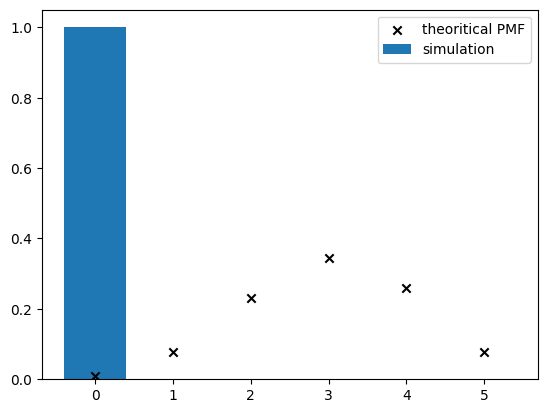

In [ ]:
#simulation and empirical probability
#simulation generates observations from an assumed model
#10,000 groups containing five independent trials p=0.6 each element is a total b/w
#0 and 5
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
sample = rng.binomial(n=5,p=0,size=10000)
k = np.arange(6)
counts = np.bincount(sample,minlength=6)
empirical = counts/len(sample)
print(empirical)
theoritical = stats.binom.pmf(k,n=5,p=0.6)
print(theoritical)
plt.bar(k,empirical,label="simulation")
plt.scatter(k,theoritical,marker="x",color="black",label="theoritical PMF")
plt.legend()
plt.show()


Section A – Data and Descriptive Statistics
1. Understanding the Variables (6 Marks)
(a) Classify the fields.
1. Course – Nominal categorical.
2. Satisfaction – Ordinal categorical.
3. Assignments completed – Discrete numerical.
4. Task completion time – Continuous numerical.
(b) Why is the mean of Student IDs not useful?

Student IDs are only used to identify students. They do not represent actual numerical values. So, calculating their mean is not meaningful.
2. Population, Sample and Scope (4 Marks)
(a) Identify population and sample.
- Population: All 240 DA students.
- Sample: Selected 30 students.
(b) Descriptive or inferential statistics?

Inferential statistics, because we use sample data to estimate the population mean.

(c) One problem with the selection method.

It creates selection bias because only students with the highest scores are selected.
3. A Useful Summary (5 Marks)
Given: 12, 15, 15, 18, 40

(a) Calculate mean, median and mode.

Mean:
\[
=\frac{12+15+15+18+40}{5}=\boxed{20}
\]

Median = 15 (middle value)

Mode = 15 (most repeated value)

(b) Which measure is better?

Median is better because 40 is an extreme value and increases the mean.

Section B – Spread and Outliers
4. Population and Sample Variation (6 Marks)
Given: 2, 4, 4, 6

(a) Population mean
\[
Mean=\frac{2+4+4+6}{4}=\boxed{4}
\]

(b) Deviations and squared deviations
X	X − Mean	Square
2	-2	4
4	0	0
4	0	0
6	2	4
Total	0	8

(c) Population variance and standard deviation
\[
Variance=\frac{8}{4}=\boxed{2}
\]

\[
SD=\sqrt{2}=\boxed{1.4142}
\]

(d) Sample variance
\[
s^2=\frac{8}{4-1}=\boxed{2.6667}
\]

5. Quartiles, Outliers and Whiskers (6 Marks)
Given: 4, 6, 7, 8, 9, 10, 12, 30

(a) Find Q1 and Q3.

Using the question's interpolation method:
\[
Q1=\boxed{6.75}
\]

\[
Q3=\boxed{10.5}
\]

(b) Find IQR.
\[
IQR=Q3-Q1
\]

\[
=10.5-6.75=\boxed{3.75}
\]

(c) Find lower and upper fences.
\[
Lower=6.75-(1.5\times3.75)=\boxed{1.125}
\]

\[
Upper=10.5+(1.5\times3.75)=\boxed{16.125}
\]

(d) Identify outliers.

30 is the outlier because it is greater than 16.125.

(e) Whisker endpoints.
- Lower whisker = 4
- Upper whisker = 12
6. Trace the Python Output (3 Marks)
Code:
import numpy as npx = np.array([1, 2, 3])print(round(np.var(x, ddof=0), 2))print(round(np.var(x, ddof=1), 2))print(x[x > np.mean(x)].tolist())



Output:
0.67
1.0
[3]


- ddof=0 – Population variance.
- ddof=1 – Sample variance.
- x > np.mean(x) – Selects values greater than the mean.
Section C – Covariance and Correlation
7. Calculate and Interpret a Paired Relationship (8 Marks)
Given:
X (Practice hours)	Y (Assessment score)
1	20
2	40
3	60
4	80

(a) Calculate mean of X and Y.
\[
\bar X=\frac{1+2+3+4}{4}=\boxed{2.5}
\]

\[
\bar Y=\frac{20+40+60+80}{4}=\boxed{50}
\]

(b) Calculate deviations and products.
X	Y	X − X̄	Y − Ȳ	Product
1	20	-1.5	-30	45
2	40	-0.5	-10	5
3	60	0.5	10	5
4	80	1.5	30	45
			Total	100

(c) Calculate sample covariance.
\[
Cov=\frac{100}{4-1}
\]

\[
\boxed{33.3333}
\]

(d) Calculate sample variance of X and Y.
- Variance of X = 1.6667
- Variance of Y = 666.6667
(e) Calculate Pearson correlation.
\[
r=\frac{Cov(X,Y)}{S_X\times S_Y}
\]

\[
\boxed{r=1}
\]

Answer: There is a perfect positive correlation between practice hours and assessment scores.
8. Evaluate the Conclusions (7 Marks)
(a) One pair has r = -0.85 and another has r = +0.40. Which is stronger?

Answer:
- -0.85 has a stronger relationship.
- Negative sign means when one variable increases, the other decreases.
(b) If Pearson correlation is zero, does it mean variables are unrelated?

Answer:

No. Zero correlation does not mean there is no relationship. Variables may have a nonlinear relationship.

(c) Every value in one column is 60. Is correlation zero or undefined?

Answer:

Correlation is undefined because the standard deviation is zero.

(d) Does correlation prove causation?

Answer:

No. Correlation does not prove causation because other factors may affect the results.

Section D – Probability Distributions
9. Choose a Probability Model (5 Marks)
(a) One visitor clicks or does not click. Probability = 0.2.

Answer: Bernoulli distribution.

- p = 0.2

(b) Six independent trials with success probability 0.5.

Answer: Binomial distribution.
- n = 6
- p = 0.5
(c) Calls arrive at four per hour. Find the model for 30 minutes.

Answer: Poisson distribution.
\[
\lambda=4\times\frac{30}{60}=\boxed{2}
\]

(d) Mean = 100 and standard deviation = 15.

Answer: Normal distribution.
- Mean = 100
- SD = 15
(e) Duration is between 5 and 15 minutes with constant density.

Answer: Uniform distribution.
- a = 5
- b = 15
10. Calculate Probabilities and Python Expressions (10 Marks)
(a) Binomial Distribution (3 Marks)

Given:
- n = 4
- p = 0.5
- q = 0.5
(i) Find P(X = 2).
\[
P(X=2)=\binom42(0.5)^2(0.5)^2
\]

\[
=6\times0.25\times0.25
\]

\[
\boxed{0.375}
\]

(ii) Find P(X ≥ 1).
\[
P(X\geq1)=1-P(X=0)
\]

\[
=1-\frac{1}{16}
\]

\[
\boxed{0.9375}
\]

(b) Normal Distribution (3 Marks)

Given:
- Mean = 50
- SD = 5
(i) Find Z-score for 60.
\[
Z=\frac{X-\mu}{SD}
\]

\[
=\frac{60-50}{5}=\boxed{2}
\]

Find P(Y > 60).
\[
=1-0.9772499
\]

\[
\boxed{0.0228}
\]

(ii) Find P(45 less than Y less than 55).
\[
=0.8413447-0.1586553
\]

\[
\boxed{0.6827}
\]

(c) Uniform Distribution (2 Marks)

Given: a = 10, b = 20

(i) Find density at 15.
\[
f(x)=\frac{1}{b-a}
\]

\[
=\frac{1}{20-10}=\boxed{0.1}
\]

(ii) Find P(12 ≤ T ≤ 16).
\[
=\frac{16-12}{20-10}
\]

\[
=\boxed{0.4}
\]

(d) SciPy Python Expressions (2 Marks)

(i) Find P(X ≥ 3).
stats.binom.sf(2, 4, 0.5)



(ii) Find P(N ≥ 4).
stats.poisson.sf(3, 3)
